# CS435 Machine Learning Project
## Predicting Employee Absence Days in Riyadh

This notebook trains Machine Learning regression models to predict employee absence days per year using employee demographic and work-related features.

**Notebook structure:**
1. Libraries and settings
2. Load and inspect the dataset
3. Data visualization
4. Data preprocessing
5. Model training
6. Model evaluation
7. Final plots and conclusion




## 1. Libraries and Settings
In this section, we import the required Python libraries and set basic visualization options.

In [1]:
# ============================================================
# 1) Libraries and Settings
# ============================================================

# Data handling libraries
import os
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Hide warning messages to keep the notebook clean
import warnings
warnings.filterwarnings("ignore")
from google.colab import files
uploaded = files.upload()

# Plot settings
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.family"] = "DejaVu Sans"
sns.set_theme(style="whitegrid")

# This folder will store all generated images
OUTPUT_DIR = "project_plots"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Libraries imported successfully.")

Saving Riyadh_Employee_Absence_Dataset_Updated.xlsx to Riyadh_Employee_Absence_Dataset_Updated.xlsx
Libraries imported successfully.


## 2. Helper Function for Saving and Showing Plots
This function saves each chart as an image and also displays it directly inside the notebook.

In [2]:
# ============================================================
# 2) Helper Function: Save and Show Figures
# ============================================================

def save_and_show(filename):
    """
    Save the current matplotlib figure, display it in the notebook,
    then close it to avoid duplicate or hidden figures.
    """
    filepath = os.path.join(OUTPUT_DIR, filename)
    plt.tight_layout()
    plt.savefig(filepath, bbox_inches="tight")
    plt.show()  # Important: this line makes the image appear in the notebook
    plt.close()
    print(f"Saved and displayed: {filepath}")

## 3. Load and Inspect Dataset
Here we load the Excel dataset and view its basic structure, columns, data types, and missing values.

In [3]:
# ============================================================
# 3) Load Dataset
# ============================================================

DATASET_PATH = "Riyadh_Employee_Absence_Dataset_Updated.xlsx"

# Check that the dataset file exists before reading it
if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset file not found: {DATASET_PATH}. "
        "Please place the Excel file in the same folder as this notebook."
    )

# Read the dataset from Excel
df = pd.read_excel(DATASET_PATH)

print(f"Dataset shape: {df.shape}")
print("\nColumns:")
print(df.columns.tolist())

# Show the first rows of the dataset
display(df.head())

Dataset shape: (10000, 14)

Columns:
['Employee_ID', 'Name', 'Gender', 'Nationality', 'Age', 'Marital_Status', 'Number_of_Children', 'District', 'Transportation_Type', 'Job_Title', 'Monthly_Salary', 'Work_Shift', 'Previous_Year_Absence_Days', 'Absence_Days_Per_Year']


,Employee_ID,Name,Gender,Nationality,Age,Marital_Status,Number_of_Children,District,Transportation_Type,Job_Title,Monthly_Salary,Work_Shift,Previous_Year_Absence_Days,Absence_Days_Per_Year
0,1,Turki Aldosari,Male,Saudi,55,Married,5,Al Yasmin,Metro,Accountant,10568,Evening,8,14
1,2,Khalid Alzahrani,Male,Yemeni,46,Single,0,Al Sulimaniyah,Car,Sales Representative,6577,Morning,15,13
2,3,Dana Alotaibi,Female,Saudi,44,Married,6,Al Sahafah,Bus,Project Manager,29764,Morning,5,8
3,4,Turki Alsubaie,Male,Saudi,33,Married,0,Al Yasmin,Metro,Project Manager,15835,Morning,7,11
4,5,Hassan Alzahrani,Male,Egyptian,22,Single,0,Al Yasmin,Car,Software Engineer,19339,Evening,0,2


In [4]:
# ============================================================
# 4) Basic Dataset Information
# ============================================================

print("Data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDescriptive statistics:")
display(df.describe())

Data types:
Employee_ID                    int64
Name                          object
Gender                        object
Nationality                   object
Age                            int64
Marital_Status                object
Number_of_Children             int64
District                      object
Transportation_Type           object
Job_Title                     object
Monthly_Salary                 int64
Work_Shift                    object
Previous_Year_Absence_Days     int64
Absence_Days_Per_Year          int64
dtype: object

Missing values:
Employee_ID                   0
Name                          0
Gender                        0
Nationality                   0
Age                           0
Marital_Status                0
Number_of_Children            0
District                      0
Transportation_Type           0
Job_Title                     0
Monthly_Salary                0
Work_Shift                    0
Previous_Year_Absence_Days    0
Absence_Days_Per_Year  

,Employee_ID,Age,Number_of_Children,Monthly_Salary,Previous_Year_Absence_Days,Absence_Days_Per_Year
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000
mean,5000.50000,41.061300,1.790200,13568.775800,6.72020,10.621300
std,2886.89568,11.196083,2.120244,5044.683077,4.65434,5.541007
min,1.00000,22.000000,0.000000,5006.000000,0.00000,0.000000
25%,2500.75000,32.000000,0.000000,9655.500000,3.00000,7.000000
50%,5000.50000,41.000000,1.000000,12858.000000,6.00000,10.000000
75%,7500.25000,51.000000,4.000000,16644.250000,10.00000,14.000000
max,10000.00000,60.000000,6.000000,29994.000000,26.00000,38.000000


## 4. Data Visualization
This section creates exploratory charts to understand the target variable and important relationships in the data.

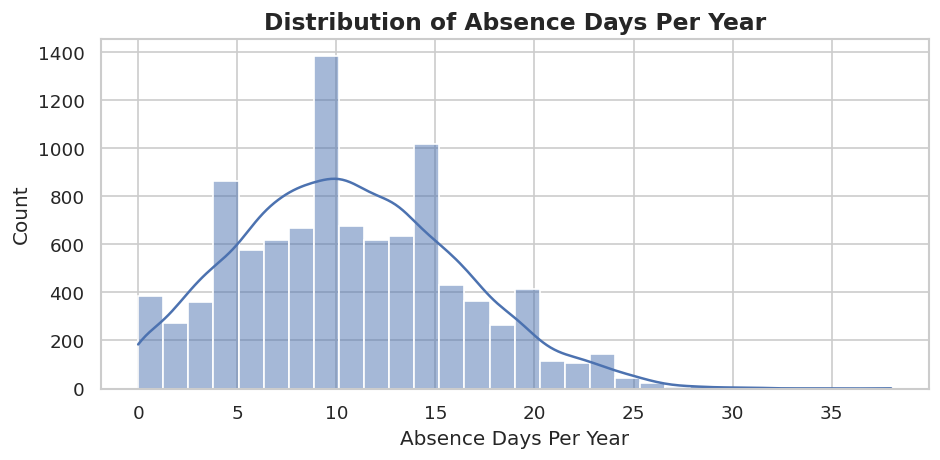

Saved and displayed: project_plots/plot_target_distribution.png


In [5]:
# ============================================================
# 5) Target Distribution
# ============================================================

# This chart shows how absence days are distributed across employees
plt.figure(figsize=(8, 4))
sns.histplot(df["Absence_Days_Per_Year"], bins=30, kde=True)
plt.title("Distribution of Absence Days Per Year", fontsize=14, fontweight="bold")
plt.xlabel("Absence Days Per Year")
plt.ylabel("Count")
save_and_show("plot_target_distribution.png")

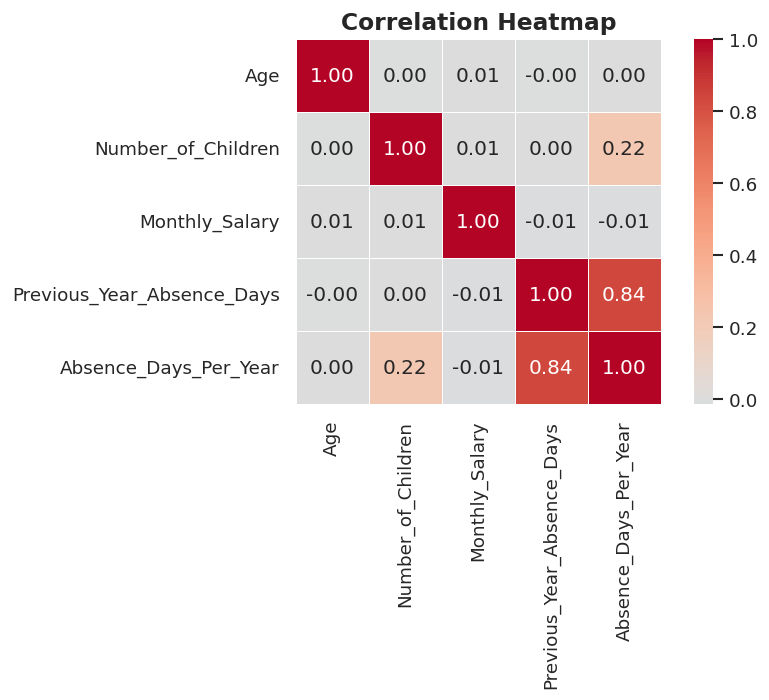

Saved and displayed: project_plots/plot_correlation_heatmap.png


In [6]:
# ============================================================
# 6) Correlation Heatmap
# ============================================================

# Correlation is calculated only for numeric columns
numeric_cols = df.select_dtypes(include=np.number).copy()

# Employee_ID is an identifier, so it should not be used in correlation analysis
if "Employee_ID" in numeric_cols.columns:
    numeric_cols = numeric_cols.drop(columns=["Employee_ID"])

corr = numeric_cols.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, square=True)
plt.title("Correlation Heatmap", fontsize=14, fontweight="bold")
save_and_show("plot_correlation_heatmap.png")

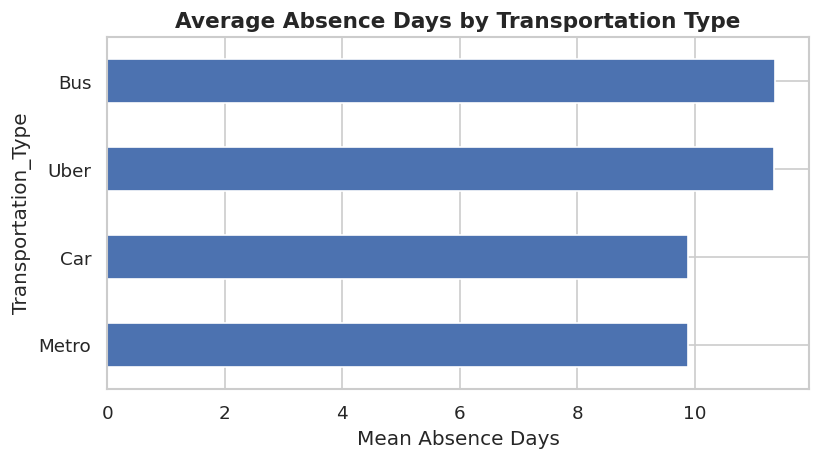

Saved and displayed: project_plots/plot_absence_by_transport.png


In [7]:
# ============================================================
# 7) Average Absence by Transportation Type
# ============================================================

# This chart compares average absence days by transportation type
plt.figure(figsize=(7, 4))
df.groupby("Transportation_Type")["Absence_Days_Per_Year"].mean().sort_values().plot(kind="barh", edgecolor="white")
plt.title("Average Absence Days by Transportation Type", fontsize=13, fontweight="bold")
plt.xlabel("Mean Absence Days")
save_and_show("plot_absence_by_transport.png")

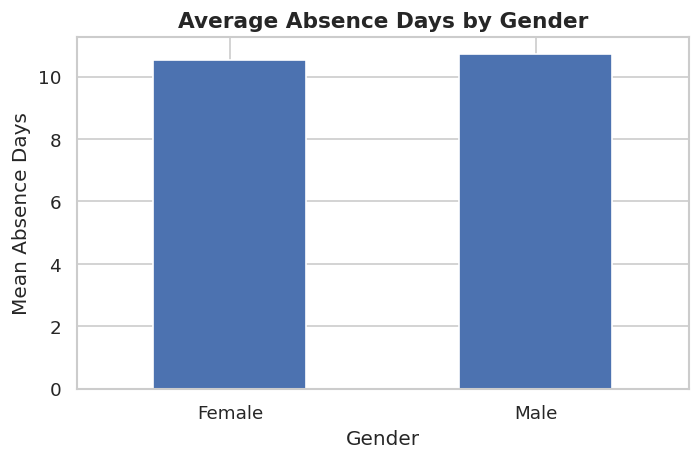

Saved and displayed: project_plots/plot_absence_by_gender.png


In [8]:
# ============================================================
# 8) Average Absence by Gender
# ============================================================

# This chart compares average absence days by gender
plt.figure(figsize=(6, 4))
df.groupby("Gender")["Absence_Days_Per_Year"].mean().plot(kind="bar", edgecolor="white", rot=0)
plt.title("Average Absence Days by Gender", fontsize=13, fontweight="bold")
plt.ylabel("Mean Absence Days")
save_and_show("plot_absence_by_gender.png")

## 5. Data Preprocessing
In this section, we prepare the dataset for machine learning by removing identifiers, encoding categorical values, splitting the data, and scaling features.

In [9]:
# ============================================================
# 9) Prepare Data for Modeling
# ============================================================

# Remove columns that are identifiers and not useful for prediction
columns_to_drop = [col for col in ["Employee_ID", "Name"] if col in df.columns]
df_model = df.drop(columns=columns_to_drop).copy()

# Convert categorical columns into numbers using LabelEncoder
categorical_cols = df_model.select_dtypes(include="object").columns.tolist()
print(f"Categorical columns to encode: {categorical_cols}")

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col].astype(str))
    label_encoders[col] = le

# Define features X and target y
X = df_model.drop(columns=["Absence_Days_Per_Year"])
y = df_model["Absence_Days_Per_Year"]

print("\nFeatures used:")
print(X.columns.tolist())
print("\nTarget: Absence_Days_Per_Year")

display(df_model.head())

Categorical columns to encode: ['Gender', 'Nationality', 'Marital_Status', 'District', 'Transportation_Type', 'Job_Title', 'Work_Shift']

Features used:
['Gender', 'Nationality', 'Age', 'Marital_Status', 'Number_of_Children', 'District', 'Transportation_Type', 'Job_Title', 'Monthly_Salary', 'Work_Shift', 'Previous_Year_Absence_Days']

Target: Absence_Days_Per_Year


,Gender,Nationality,Age,Marital_Status,Number_of_Children,District,Transportation_Type,Job_Title,Monthly_Salary,Work_Shift,Previous_Year_Absence_Days,Absence_Days_Per_Year
0,1,5,55,0,5,14,2,0,10568,0,8,14
1,1,9,46,1,0,12,1,8,6577,1,15,13
2,0,5,44,0,6,10,0,7,29764,1,5,8
3,1,5,33,0,0,14,2,7,15835,1,7,11
4,1,0,22,1,0,14,1,9,19339,0,0,2


In [10]:
# ============================================================
# 10) Train/Test Split and Scaling
# ============================================================

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size:     {X_test.shape[0]} samples")

# Scaling is used for Gradient Boosting in this notebook
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training set size: 8000 samples
Test set size:     2000 samples


## 6. Model Training
We train two regression models: Random Forest Regressor and Gradient Boosting Regressor.

In [11]:
# ============================================================
# 11) Train Random Forest Regressor
# ============================================================

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model using the original training features
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Regressor trained successfully.")

Random Forest Regressor trained successfully.


In [12]:
# ============================================================
# 12) Train Gradient Boosting Regressor
# ============================================================

gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    random_state=42
)

# Train the model using scaled features
gb_model.fit(X_train_scaled, y_train)
y_pred_gb = gb_model.predict(X_test_scaled)

print("Gradient Boosting Regressor trained successfully.")

Gradient Boosting Regressor trained successfully.


## 7. Model Evaluation
We evaluate models using MAE, RMSE, and R².

In [13]:
# ============================================================
# 13) Evaluation Function
# ============================================================

def evaluate_model(name, y_true, y_pred):
    """
    Calculate common regression metrics:
    - MAE: Average absolute error
    - RMSE: Error with stronger penalty for large mistakes
    - R²: How well the model explains the target variation
    """
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"\n{'='*40}")
    print(f"  {name}")
    print(f"{'='*40}")
    print(f"  MAE  : {mae:.4f}")
    print(f"  RMSE : {rmse:.4f}")
    print(f"  R²   : {r2:.4f}")

    return {"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2}

results = [
    evaluate_model("Random Forest Regressor", y_test, y_pred_rf),
    evaluate_model("Gradient Boosting Regressor", y_test, y_pred_gb)
]

results_df = pd.DataFrame(results)
print("\nModel Comparison:")
display(results_df)


  Random Forest Regressor
  MAE  : 2.0639
  RMSE : 2.5102
  R²   : 0.8001

  Gradient Boosting Regressor
  MAE  : 1.9869
  RMSE : 2.4063
  R²   : 0.8163

Model Comparison:


,Model,MAE,RMSE,R2
0,Random Forest Regressor,2.063874,2.510246,0.800115
1,Gradient Boosting Regressor,1.986931,2.406317,0.816323


## 8. Final Visualizations
These plots help explain model behavior and compare model performance.

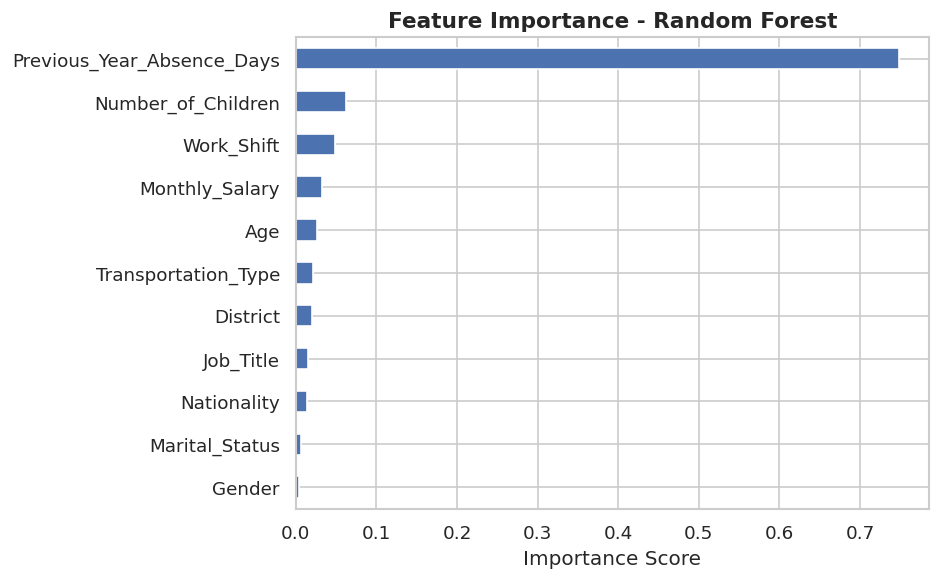

Saved and displayed: project_plots/plot_feature_importance.png


In [14]:
# ============================================================
# 14) Feature Importance - Random Forest
# ============================================================

# Feature importance shows which variables contributed most to the Random Forest predictions
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importances.plot(kind="barh", edgecolor="white")
plt.title("Feature Importance - Random Forest", fontsize=13, fontweight="bold")
plt.xlabel("Importance Score")
save_and_show("plot_feature_importance.png")

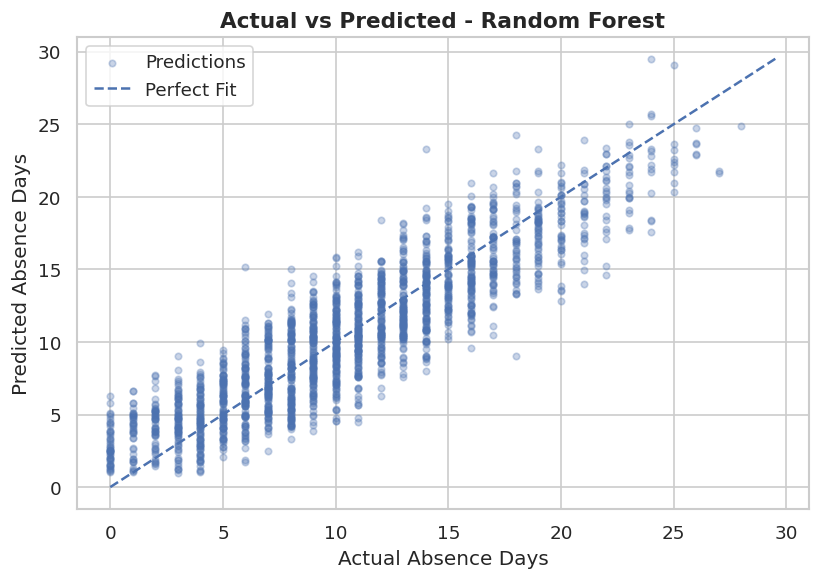

Saved and displayed: project_plots/plot_actual_vs_predicted_rf.png


In [15]:
# ============================================================
# 15) Actual vs Predicted - Random Forest
# ============================================================

# Points close to the diagonal line mean better predictions
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_rf, alpha=0.3, s=15, label="Predictions")
min_val = min(y_test.min(), y_pred_rf.min(), y_pred_gb.min())
max_val = max(y_test.max(), y_pred_rf.max(), y_pred_gb.max())
plt.plot([min_val, max_val], [min_val, max_val], "--", lw=1.5, label="Perfect Fit")
plt.xlabel("Actual Absence Days")
plt.ylabel("Predicted Absence Days")
plt.title("Actual vs Predicted - Random Forest", fontsize=13, fontweight="bold")
plt.legend()
save_and_show("plot_actual_vs_predicted_rf.png")

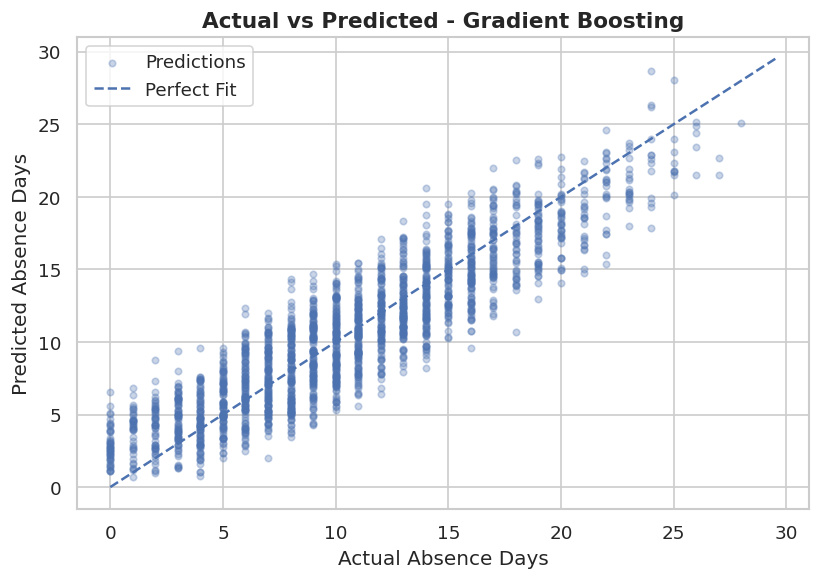

Saved and displayed: project_plots/plot_actual_vs_predicted_gb.png


In [16]:
# ============================================================
# 16) Actual vs Predicted - Gradient Boosting
# ============================================================

# Points close to the diagonal line mean better predictions
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_gb, alpha=0.3, s=15, label="Predictions")
plt.plot([min_val, max_val], [min_val, max_val], "--", lw=1.5, label="Perfect Fit")
plt.xlabel("Actual Absence Days")
plt.ylabel("Predicted Absence Days")
plt.title("Actual vs Predicted - Gradient Boosting", fontsize=13, fontweight="bold")
plt.legend()
save_and_show("plot_actual_vs_predicted_gb.png")

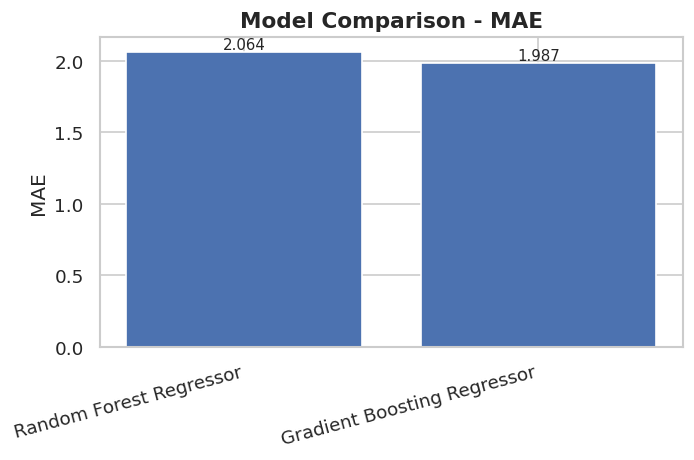

Saved and displayed: project_plots/plot_model_comparison_MAE.png


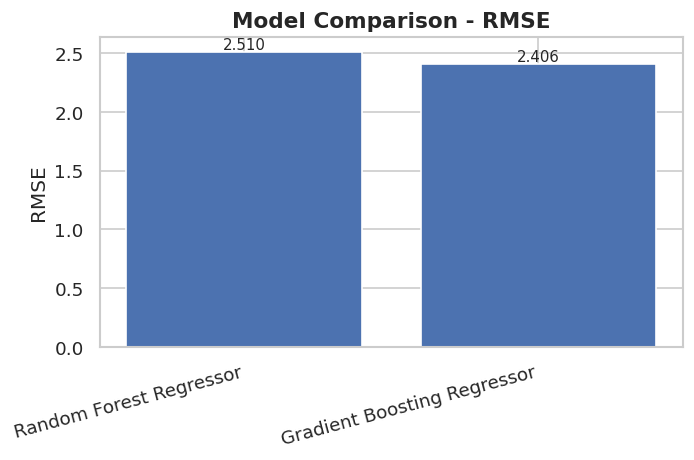

Saved and displayed: project_plots/plot_model_comparison_RMSE.png


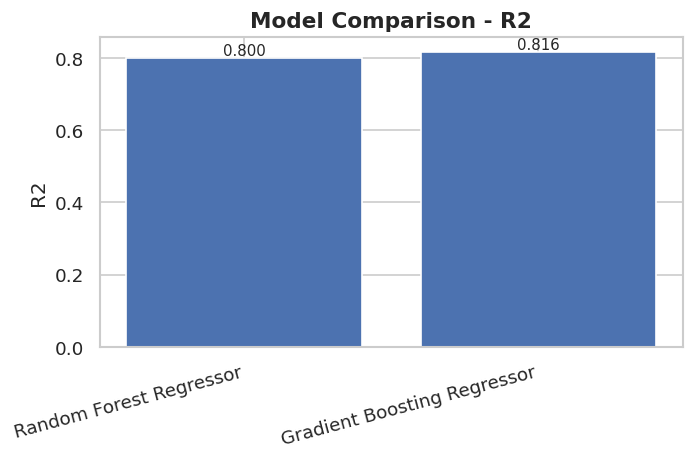

Saved and displayed: project_plots/plot_model_comparison_R2.png


In [17]:
# ============================================================
# 17) Model Performance Comparison
# ============================================================

# Compare the two models using MAE, RMSE, and R²
metrics = ["MAE", "RMSE", "R2"]

for metric in metrics:
    plt.figure(figsize=(6, 4))
    bars = plt.bar(results_df["Model"], results_df[metric], edgecolor="white")
    plt.title(f"Model Comparison - {metric}", fontsize=13, fontweight="bold")
    plt.ylabel(metric)
    plt.xticks(rotation=15, ha="right")

    # Add metric values above each bar
    for bar, value in zip(bars, results_df[metric]):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

    save_and_show(f"plot_model_comparison_{metric}.png")

## 9. Conclusion
The final cell selects the best model based on the lowest RMSE value.

In [18]:
# ============================================================
# 18) Final Conclusion
# ============================================================

# Lower RMSE means better prediction accuracy for this regression problem
best_model_row = results_df.sort_values(by="RMSE", ascending=True).iloc[0]

print("✅ All outputs generated successfully!")
print(f"Best model based on RMSE: {best_model_row['Model']}")
print(f"MAE  = {best_model_row['MAE']:.4f}")
print(f"RMSE = {best_model_row['RMSE']:.4f}")
print(f"R²   = {best_model_row['R2']:.4f}")

✅ All outputs generated successfully!
Best model based on RMSE: Gradient Boosting Regressor
MAE  = 1.9869
RMSE = 2.4063
R²   = 0.8163
